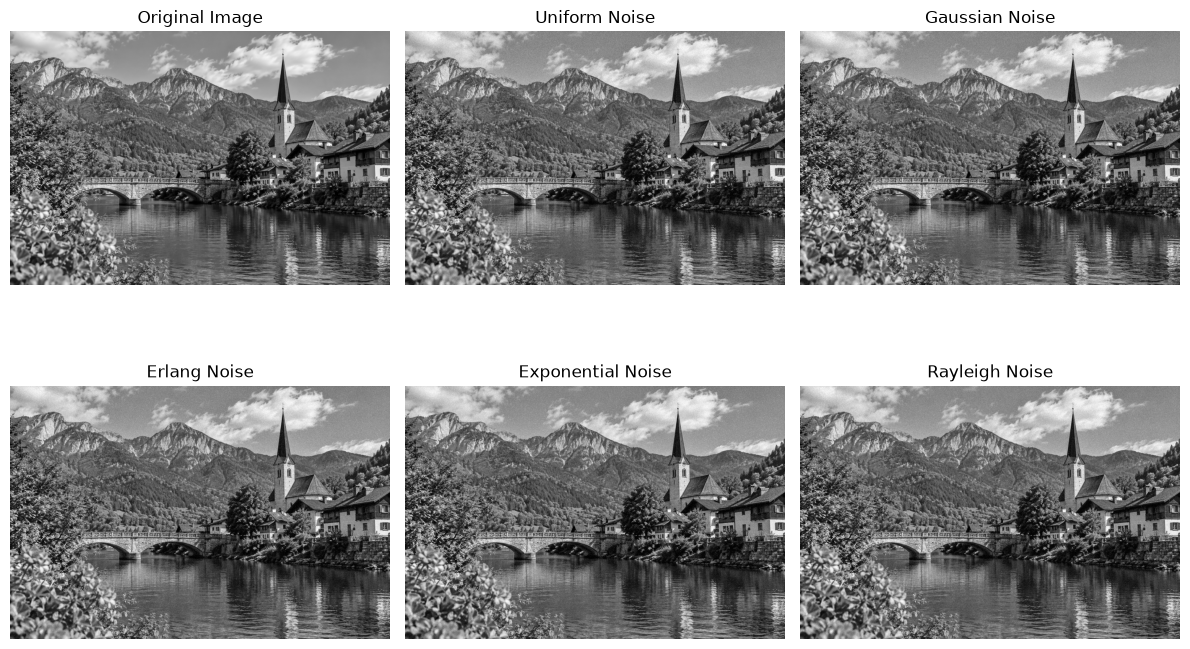

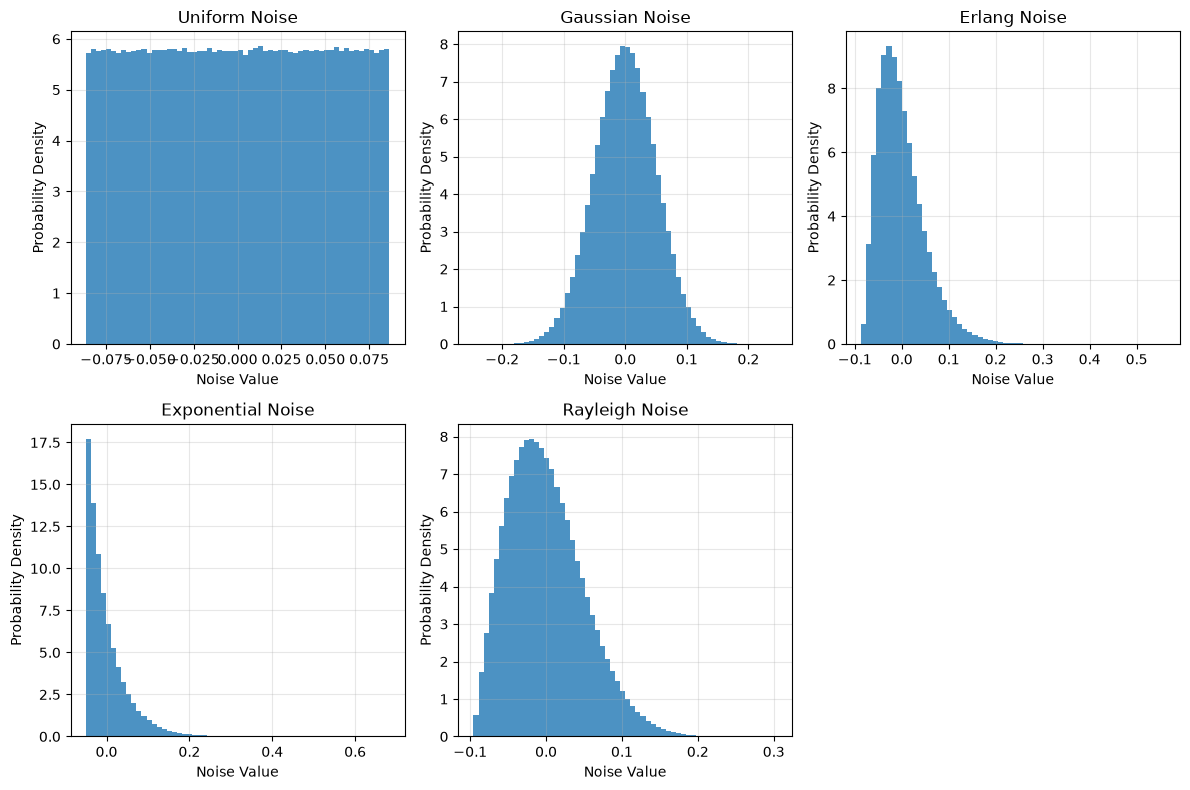

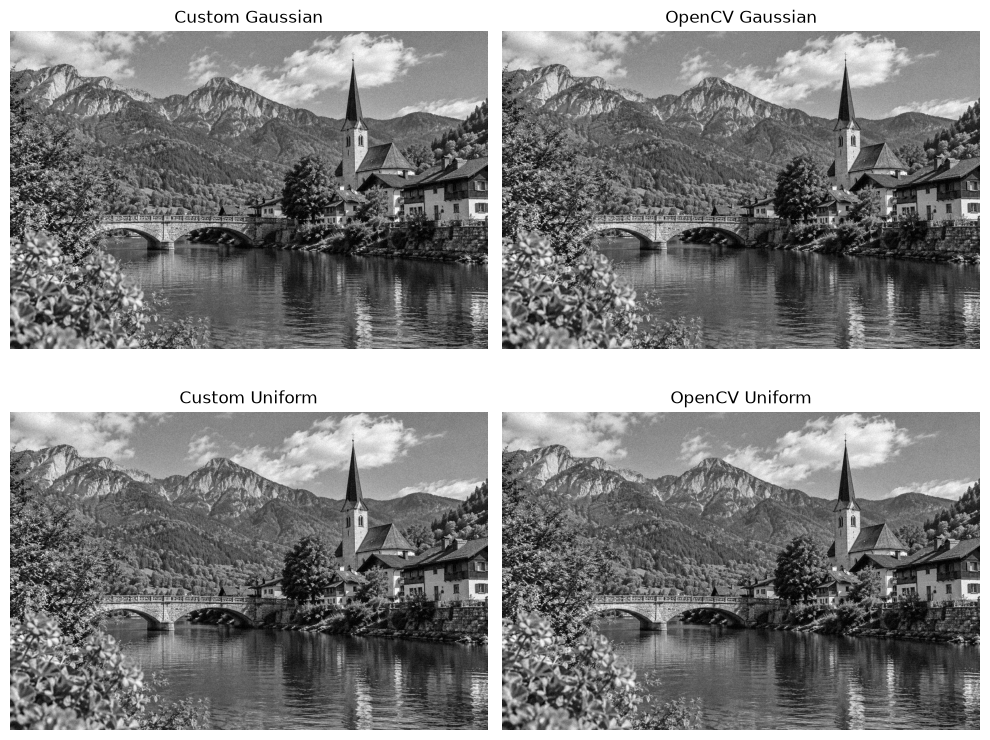


NOISE DISTRIBUTION STATISTICS
-------------------------------------------------------
Uniform Noise        Mean = 0.00003, Variance = 0.00250
Gaussian Noise       Mean = 0.00005, Variance = 0.00250
Erlang Noise         Mean = 0.00003, Variance = 0.00250
Exponential Noise    Mean = 0.00003, Variance = 0.00250
Rayleigh Noise       Mean = -0.00004, Variance = 0.00250

OPENCV BUILT-IN GENERATOR STATISTICS
-------------------------------------------------------
OpenCV Gaussian: Mean = 0.00002, Variance = 0.00250
OpenCV Uniform: Mean = 0.00003, Variance = 0.00250

Assignment completed successfully.


In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Assignment 8: Generation of Noise Distributions
# --------------------------------------------------

# Read input image in grayscale
img = cv2.imread("input7.png", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError(
        "input7.png not found. Check the image path."
    )

# Convert image to floating-point format [0, 1]
img = img.astype(np.float32) / 255.0

height, width = img.shape

# Random number generator
rng = np.random.default_rng()

# Common noise standard deviation
sigma = 0.05


# --------------------------------------------------
# Function to add noise to an image
# --------------------------------------------------
def add_noise(image, noise):
    noisy_image = image + noise
    noisy_image = np.clip(noisy_image, 0, 1)
    return noisy_image


# --------------------------------------------------
# 1. UNIFORM NOISE
# --------------------------------------------------

# Uniform noise between -sqrt(3)*sigma and +sqrt(3)*sigma
# This gives theoretical mean 0 and variance sigma^2

a = -np.sqrt(3) * sigma
b = np.sqrt(3) * sigma

uniform_noise = rng.uniform(
    a, b, size=(height, width)
).astype(np.float32)

uniform_img = add_noise(img, uniform_noise)


# --------------------------------------------------
# 2. GAUSSIAN NOISE
# --------------------------------------------------

mu = 0

gaussian_noise = rng.normal(
    mu, sigma, size=(height, width)
).astype(np.float32)

gaussian_img = add_noise(img, gaussian_noise)


# --------------------------------------------------
# 3. ERLANG NOISE
# --------------------------------------------------

# Erlang distribution with shape k and rate lambda
# It is generated by summing k exponential variables

k = 3
lam = 2.0

erlang_raw = np.zeros(
    (height, width), dtype=np.float32
)

for i in range(k):
    u = rng.random((height, width))
    u = np.maximum(u, 1e-10)

    erlang_raw += -np.log(u) / lam

# Center the noise and scale its standard deviation
erlang_mean = k / lam
erlang_std = np.sqrt(k) / lam

erlang_noise = (
    (erlang_raw - erlang_mean)
    * (sigma / erlang_std)
).astype(np.float32)

erlang_img = add_noise(img, erlang_noise)


# --------------------------------------------------
# 4. EXPONENTIAL NOISE
# --------------------------------------------------

lam_exp = 2.0

exponential_raw = rng.exponential(
    scale=1 / lam_exp,
    size=(height, width)
).astype(np.float32)

# Center the distribution and scale the noise
exponential_mean = 1 / lam_exp
exponential_std = 1 / lam_exp

exponential_noise = (
    (exponential_raw - exponential_mean)
    * (sigma / exponential_std)
).astype(np.float32)

exponential_img = add_noise(img, exponential_noise)


# --------------------------------------------------
# 5. RAYLEIGH NOISE
# --------------------------------------------------

# PDF: p(z) = (2/b)*(z-a)*exp(-(z-a)^2/b)
# z >= a

a_ray = 0
b_ray = 2.0

u = rng.random((height, width)).astype(np.float32)
u = np.clip(u, 1e-10, 1 - 1e-7)

rayleigh_raw = a_ray + np.sqrt(
    -b_ray * np.log(1 - u)
)

# Theoretical mean and standard deviation
rayleigh_mean = a_ray + np.sqrt(
    b_ray * np.pi
) / 2

rayleigh_std = np.sqrt(
    b_ray * (4 - np.pi) / 4
)

# Center and scale the noise
rayleigh_noise = (
    (rayleigh_raw - rayleigh_mean)
    * (sigma / rayleigh_std)
).astype(np.float32)

rayleigh_img = add_noise(img, rayleigh_noise)


# --------------------------------------------------
# DISPLAY ORIGINAL AND NOISY IMAGES
# --------------------------------------------------

images = [
    ("Original Image", img),
    ("Uniform Noise", uniform_img),
    ("Gaussian Noise", gaussian_img),
    ("Erlang Noise", erlang_img),
    ("Exponential Noise", exponential_img),
    ("Rayleigh Noise", rayleigh_img)
]

plt.figure(figsize=(12, 8))

for i, (title, image) in enumerate(images):
    plt.subplot(2, 3, i + 1)

    plt.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# HISTOGRAMS OF GENERATED NOISE
# --------------------------------------------------

noises = [
    ("Uniform Noise", uniform_noise),
    ("Gaussian Noise", gaussian_noise),
    ("Erlang Noise", erlang_noise),
    ("Exponential Noise", exponential_noise),
    ("Rayleigh Noise", rayleigh_noise)
]

plt.figure(figsize=(12, 8))

for i, (title, noise) in enumerate(noises):
    plt.subplot(2, 3, i + 1)

    plt.hist(
        noise.ravel(),
        bins=60,
        density=True,
        alpha=0.8
    )

    plt.title(title)
    plt.xlabel("Noise Value")
    plt.ylabel("Probability Density")
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# COMPARISON WITH OPENCV BUILT-IN GENERATORS
# --------------------------------------------------

# Gaussian noise generated using cv2.randn()
opencv_gaussian_noise = np.zeros(
    (height, width), dtype=np.float32
)

cv2.randn(
    opencv_gaussian_noise,
    0,
    sigma
)

opencv_gaussian_img = add_noise(
    img,
    opencv_gaussian_noise
)


# Uniform noise generated using cv2.randu()
opencv_uniform_noise = np.zeros(
    (height, width), dtype=np.float32
)

cv2.randu(
    opencv_uniform_noise,
    float(a),
    float(b)
)

opencv_uniform_img = add_noise(
    img,
    opencv_uniform_noise
)


# Display comparison
comparison = [
    ("Custom Gaussian", gaussian_img),
    ("OpenCV Gaussian", opencv_gaussian_img),
    ("Custom Uniform", uniform_img),
    ("OpenCV Uniform", opencv_uniform_img)
]

plt.figure(figsize=(10, 8))

for i, (title, image) in enumerate(comparison):
    plt.subplot(2, 2, i + 1)

    plt.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# PRINT NOISE STATISTICS
# --------------------------------------------------

print("\nNOISE DISTRIBUTION STATISTICS")
print("-" * 55)

for title, noise in noises:
    print(
        f"{title:20s} "
        f"Mean = {np.mean(noise):.5f}, "
        f"Variance = {np.var(noise):.5f}"
    )


print("\nOPENCV BUILT-IN GENERATOR STATISTICS")
print("-" * 55)

print(
    "OpenCV Gaussian: "
    f"Mean = {np.mean(opencv_gaussian_noise):.5f}, "
    f"Variance = {np.var(opencv_gaussian_noise):.5f}"
)

print(
    "OpenCV Uniform: "
    f"Mean = {np.mean(opencv_uniform_noise):.5f}, "
    f"Variance = {np.var(opencv_uniform_noise):.5f}"
)

print("\nAssignment completed successfully.")
